## Chargement et decouverte
### provide imports

In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path 
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, root_mean_squared_error


### load dataset

In [60]:
df = pd.read_csv(r"C:\Users\Youcode\Documents\DEV_AI\sprint_1\Azure1\data\raw\dataset-electric.csv")
ARTIFACTS = Path(r'C:\Users\Youcode\Documents\DEV_AI\sprint_1\Azure1\artifacts')

In [61]:
df["Datetime"] = pd.to_datetime(df["Datetime"],errors="coerce",format="%Y-%m-%d %H:%M:%S")

In [62]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145366 entries, 0 to 145365
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Datetime  145366 non-null  datetime64[ns]
 1   PJME_MW   145366 non-null  float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 2.2 MB


In [63]:
df.shape

(145366, 2)

In [64]:
df.describe()

,Datetime,PJME_MW
count,145366,145366.000000
mean,2010-04-18 03:25:25.999202048,32080.222831
min,2002-01-01 01:00:00,14544.000000
25%,2006-02-23 14:15:00,27573.000000
50%,2010-04-18 04:30:00,31421.000000
75%,2014-06-10 18:45:00,35650.000000
max,2018-08-03 00:00:00,62009.000000
std,NaN,6464.012166


In [65]:
df.duplicated().sum()

np.int64(0)

## Nettoyage

In [66]:
df = df.sort_values("Datetime").reset_index(drop=True)

print("Missing values:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("Duplicate timestamps:", df["Datetime"].duplicated().sum())

print("Invalid consumption:", (df["PJME_MW"] <= 0).sum())

Missing values:
Datetime    0
PJME_MW     0
dtype: int64

Duplicate rows: 0
Duplicate timestamps: 4
Invalid consumption: 0


In [67]:
time_diff = df["Datetime"].diff()
time_diff.value_counts()


Datetime
0 days 01:00:00    145331
0 days 02:00:00        30
0 days 00:00:00         4
Name: count, dtype: int64

In [68]:
gaps = df[time_diff > pd.Timedelta(hours=1)]
gaps[["Datetime"]].head()

C:\Users\Youcode\AppData\Local\Temp\ipykernel_16496\545971380.py:1: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  gaps = df[time_diff > pd.Timedelta(hours=1)]


,Datetime
2306,2002-04-07 04:00:00
7176,2002-10-27 03:00:00
11040,2003-04-06 04:00:00
15910,2003-10-26 03:00:00
19774,2004-04-04 04:00:00


## EDA

In [69]:
def save_plt(path):
    plt.savefig(path, dpi='figure')
    plt.show()

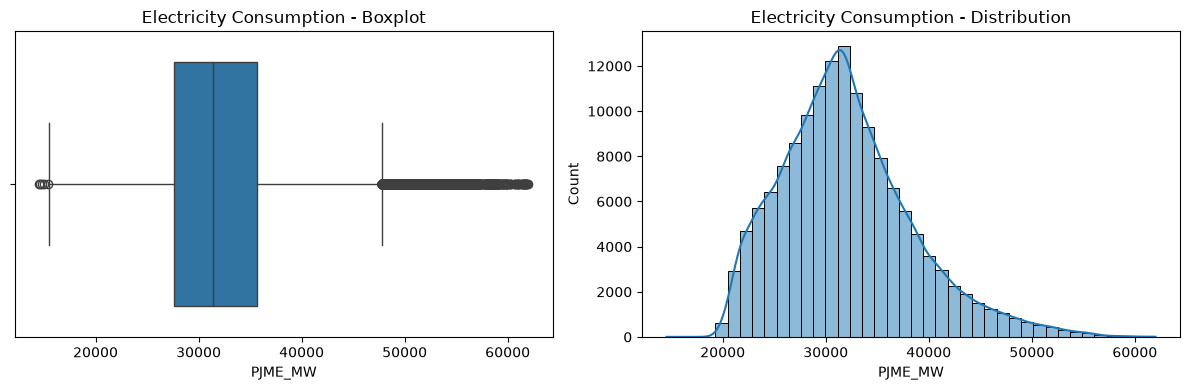

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x="PJME_MW", ax=axes[0])
axes[0].set_title("Electricity Consumption - Boxplot")

sns.histplot(data=df, x="PJME_MW", bins=40, kde=True, ax=axes[1])
axes[1].set_title("Electricity Consumption - Distribution")

plt.tight_layout()
save_plt(ARTIFACTS / "hist_box_plot.png")

In [71]:
df.columns

Index(['Datetime', 'PJME_MW'], dtype='object')

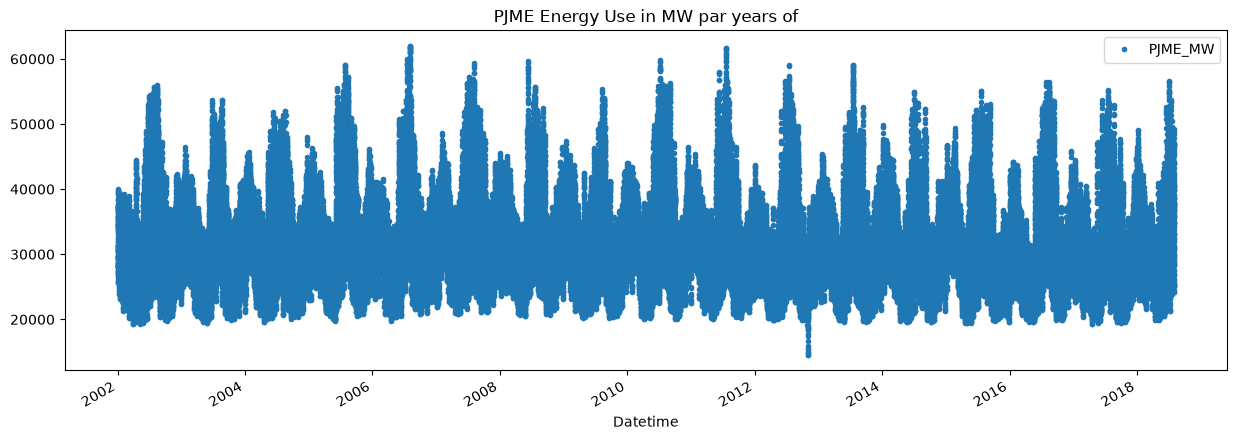

In [72]:
df.plot(x="Datetime",
        y="PJME_MW",
        style='.',
        figsize=(15, 5),
        title='PJME Energy Use in MW par years of')
save_plt(ARTIFACTS/ "PJME_use_MW.png")

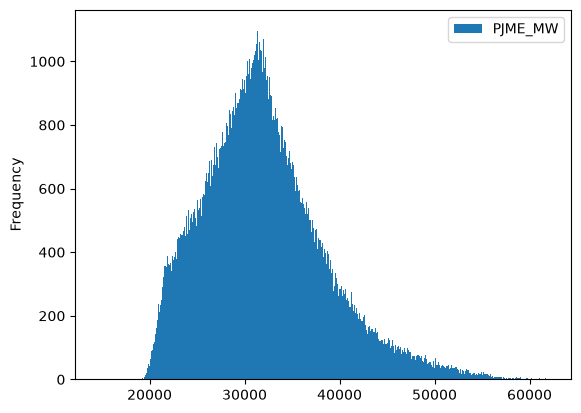

In [73]:
df.plot(kind="hist",bins=500,)
save_plt(ARTIFACTS / "hist.png")

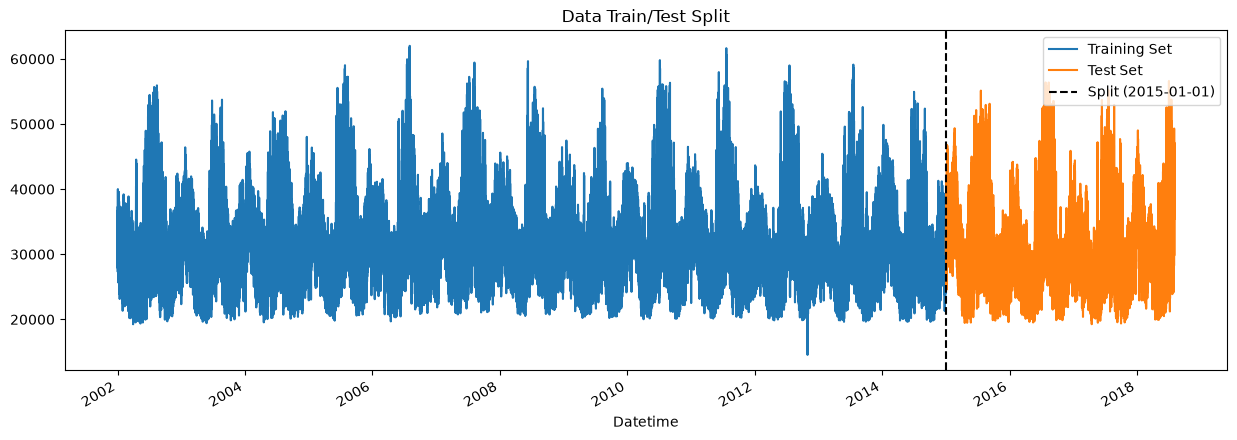

In [74]:
df["Datetime"] = pd.to_datetime(df["Datetime"])

split_date = pd.Timestamp("2015-01-01")
train = df.loc[df["Datetime"] < split_date]
test = df.loc[df["Datetime"] >= split_date]

fig, ax = plt.subplots(figsize=(15, 5))
train.plot(x="Datetime", y="PJME_MW", ax=ax, label="Training Set", title="Data Train/Test Split")
test.plot(x="Datetime", y="PJME_MW", ax=ax, label="Test Set")

ax.axvline(split_date, color="black", ls="--", label="Split (2015-01-01)")
ax.legend()
save_plt(ARTIFACTS / "train_test.png")

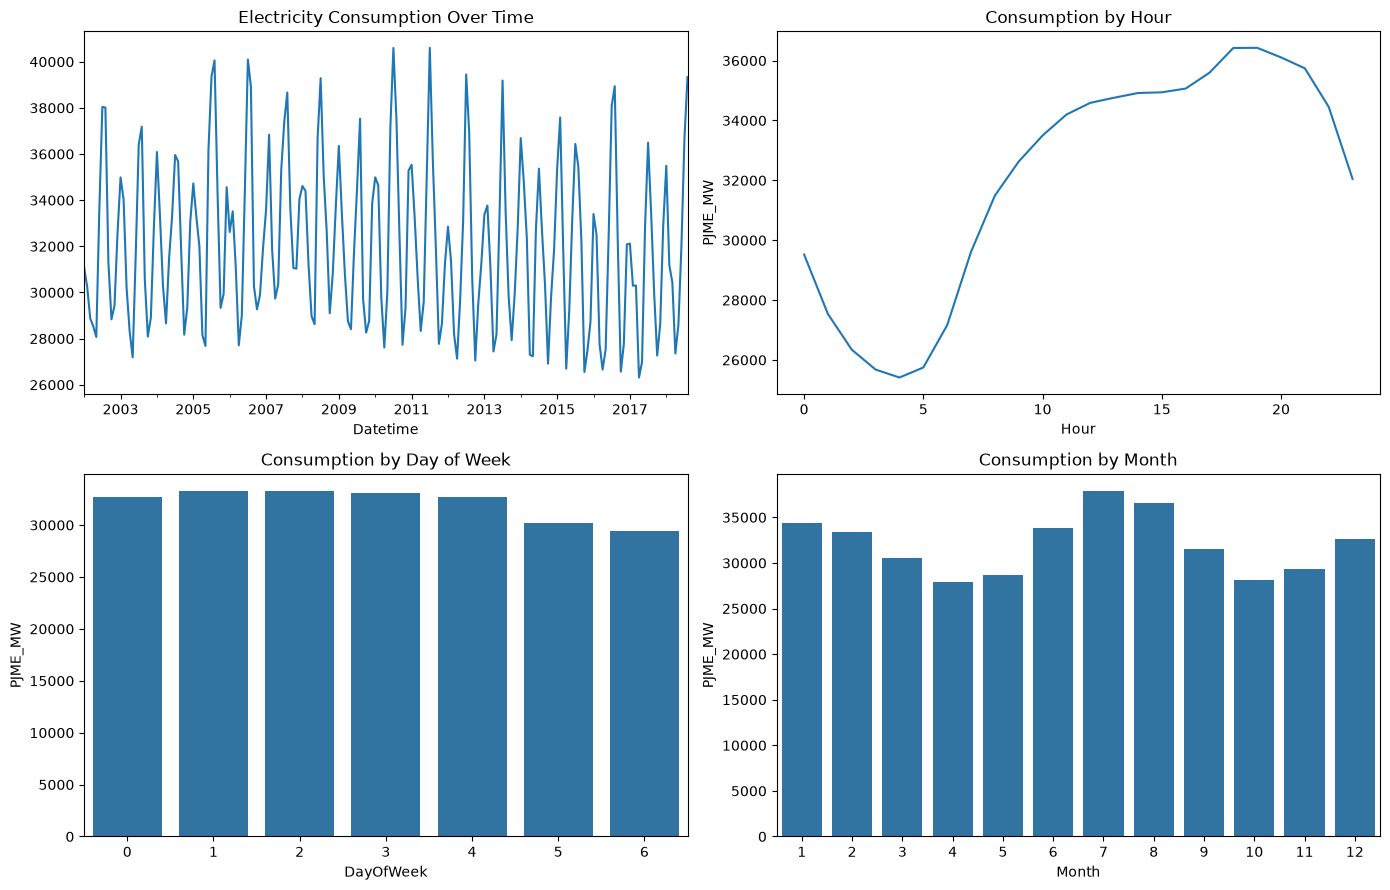

In [75]:
eda = df.sort_values("Datetime").copy()

eda["Hour"] = eda["Datetime"].dt.hour
eda["DayOfWeek"] = eda["Datetime"].dt.dayofweek
eda["Month"] = eda["Datetime"].dt.month

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

eda.set_index("Datetime")["PJME_MW"].resample("ME").mean().plot(
    ax=axes[0, 0],
    title="Electricity Consumption Over Time"
)

sns.lineplot(
    data=eda, x="Hour", y="PJME_MW",
    estimator="mean", errorbar=None, ax=axes[0, 1]
)
axes[0, 1].set_title("Consumption by Hour")

sns.barplot(
    data=eda, x="DayOfWeek", y="PJME_MW",
    errorbar=None, ax=axes[1, 0]
)
axes[1, 0].set_title("Consumption by Day of Week")

sns.barplot(
    data=eda, x="Month", y="PJME_MW",
    errorbar=None, ax=axes[1, 1]
)
axes[1, 1].set_title("Consumption by Month")

plt.tight_layout()
save_plt(ARTIFACTS / "consumption_over_t_h_d_m.png")

In [76]:
df = (
    df.groupby("Datetime", as_index=False)["PJME_MW"].mean()
    .sort_values("Datetime")
    .reset_index(drop=True)
)

### Feature Engeniering

In [77]:
df_model = df.sort_values("Datetime").reset_index(drop=True).copy()

df_model["Hour"] = df_model["Datetime"].dt.hour
df_model["DayOfWeek"] = df_model["Datetime"].dt.dayofweek
df_model["Month"] = df_model["Datetime"].dt.month
df_model["Year"] = df_model["Datetime"].dt.year
df_model["IsWeekend"] = (df_model["DayOfWeek"] >= 5).astype(int)

df_model.head()

,Datetime,PJME_MW,Hour,DayOfWeek,Month,Year,IsWeekend
0,2002-01-01 01:00:00,30393.0,1,1,1,2002,0
1,2002-01-01 02:00:00,29265.0,2,1,1,2002,0
2,2002-01-01 03:00:00,28357.0,3,1,1,2002,0
3,2002-01-01 04:00:00,27899.0,4,1,1,2002,0
4,2002-01-01 05:00:00,28057.0,5,1,1,2002,0


In [78]:
df_model["lag24"] = df_model["PJME_MW"].shift(24)
df_model["lag168"] = df_model["PJME_MW"].shift(168)

In [79]:
df_model["roll_24"] = (
    df_model["PJME_MW"]
    .shift(1)
    .rolling(window=24)
    .mean()
)

In [80]:
df_model[["lag24", "lag168", "roll_24"]].isna().sum()

lag24       24
lag168     168
roll_24     24
dtype: int64

In [81]:
df_model = df_model.dropna(
    subset=["lag24", "lag168", "roll_24"]
).reset_index(drop=True)

## prepare data

In [82]:
df.columns

Index(['Datetime', 'PJME_MW'], dtype='object')

In [83]:
X = df_model.drop(columns=['Datetime', 'PJME_MW'])
y = df_model["PJME_MW"]

In [84]:
split = int(len(df_model) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:] 

In [85]:
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((116155, 8), (29039, 8), (116155,), (29039,))

In [86]:
pipline = Pipeline(steps=[
    ("standar",StandardScaler()),
    ("regressor",LinearRegression())
])
pip = make_pipeline(StandardScaler(),Ridge(alpha=0.1))


In [87]:
pipline.fit(X_train,y_train)
pip.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Hour','DayOfWeek','Month',...,'lag24','lag168','roll_24']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [88]:
y_pred1 = pipline.predict(X_test)
y_pred2 = pip.predict(X_test)

In [89]:
print("Model MAE:", mean_absolute_error(y_test, y_pred1))
print("Model RMSE:", root_mean_squared_error(y_test, y_pred1))
print("Baseline MAE:", mean_absolute_error(y_test, X_test["lag24"]))

Model MAE: 1837.4598397296074
Model RMSE: 2448.864377033232
Baseline MAE: 2183.9943179861566


In [90]:
print("Model MAE:", mean_absolute_error(y_test, y_pred2))
print("Model RMSE:", root_mean_squared_error(y_test, y_pred2))
print("Baseline MAE:", mean_absolute_error(y_test, X_test["lag24"]))

Model MAE: 1837.4598661364964
Model RMSE: 2448.864352931361
Baseline MAE: 2183.9943179861566


In [91]:
# Illustrative values: replace lags and rolling mean with real history
t = pd.Timestamp("2018-08-03 01:00:00")

new_data = pd.DataFrame([{
    "Hour": t.hour,
    "DayOfWeek": t.dayofweek,  # Monday = 0
    "Month": t.month,
    "Year": t.year,
    "IsWeekend": int(t.dayofweek >= 5),
    "lag24": 31000.0,
    "lag168": 32500.0,
    "roll_24": 31800.0,
}])[X_train.columns]

prediction = pipline.predict(new_data)
print("Predicted consumption:", prediction[0], "MW")

Predicted consumption: 29630.627394276547 MW


## Evaluation: MAE, RMSE, R² and MAPE

Compare both fitted pipelines and the lag24 baseline on identical test timestamps. MAE and RMSE are in MW; MAPE is expressed as a percentage. Lower errors are better; higher R² is better (1 is perfect, 0 matches the test-mean reference). These results represent rolling predictions with observed history available, not a fixed-origin multi-hour forecast. Linear Regression and Ridge can overlap at the displayed precision.


In [92]:
from sklearn.metrics import (
    mean_absolute_error, root_mean_squared_error,
    r2_score, mean_absolute_percentage_error,
)

# All three approaches are evaluated on the same chronological test rows.
predictions = {
    "Baseline (lag24)": X_test["lag24"].to_numpy(),
    "Linear Regression": y_pred1,
    "Ridge (alpha=0.1)": y_pred2,
}

# MAPE is undefined for zero targets; do not silently discard test rows.
if (y_test == 0).any():
    raise ValueError("MAPE requires nonzero targets; define a zero-target policy first.")

metrics = pd.DataFrame({
    name: {
        "MAE (MW)": mean_absolute_error(y_test, pred),
        "RMSE (MW)": root_mean_squared_error(y_test, pred),
        "R²": r2_score(y_test, pred),
        "MAPE (%)": 100 * mean_absolute_percentage_error(y_test, pred),
    }
    for name, pred in predictions.items()
}).T.rename_axis("Model")

print(f"Evaluation on {len(y_test):,} identical test observations")
print(metrics.to_string(float_format=lambda value: f"{value:.4f}"))

ARTIFACTS.mkdir(parents=True, exist_ok=True)
metrics.to_csv(ARTIFACTS / "model_comparison.csv")


Evaluation on 29,039 identical test observations
                   MAE (MW)  RMSE (MW)     R²  MAPE (%)
Model                                                  
Baseline (lag24)  2183.9943  3008.9299 0.7851    6.9302
Linear Regression 1837.4598  2448.8644 0.8577    5.8177
Ridge (alpha=0.1) 1837.4599  2448.8644 0.8577    5.8177


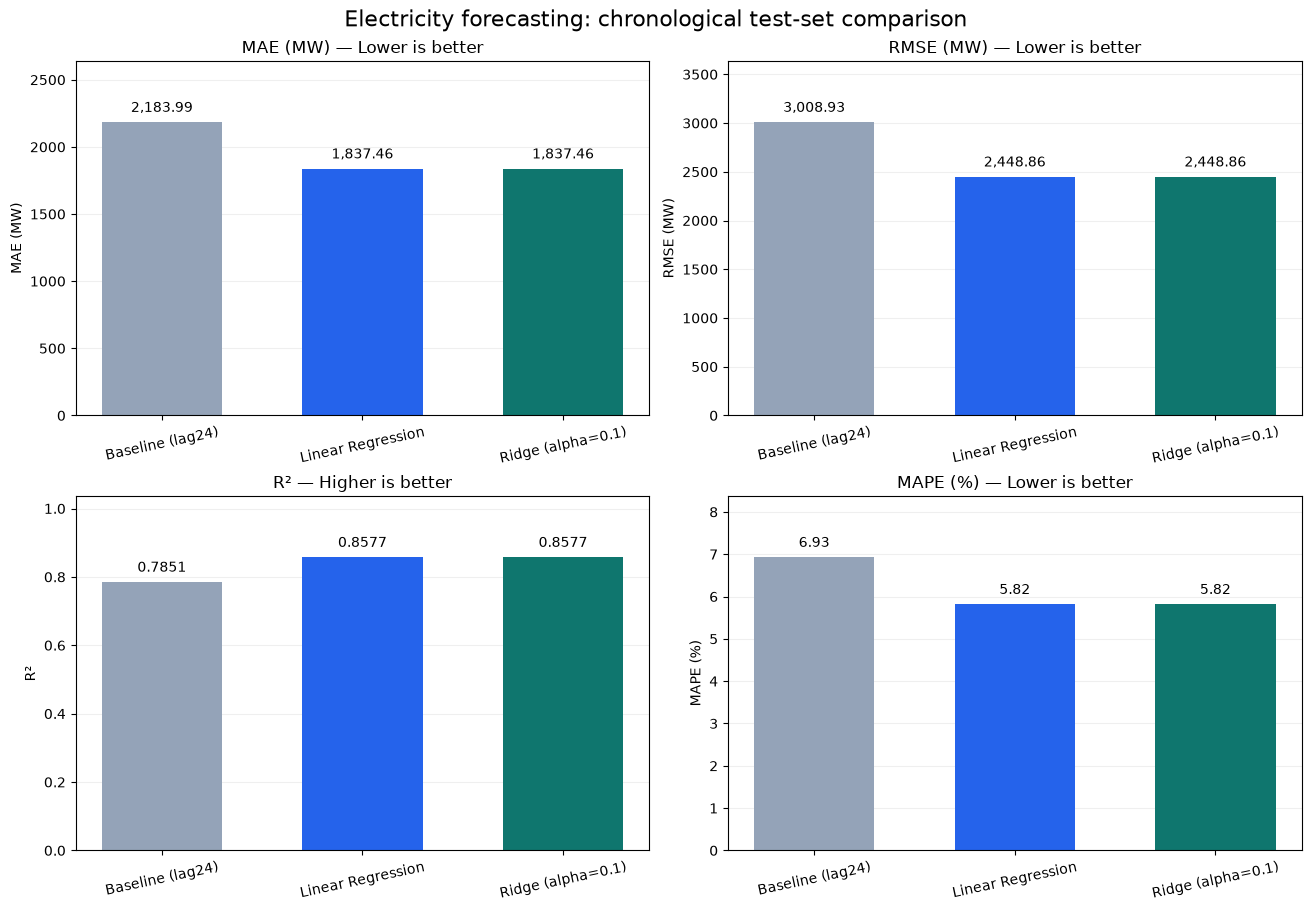

In [93]:
colors = ["#94a3b8", "#2563eb", "#0f766e"]
fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout="constrained")
for ax, metric in zip(axes.flat, metrics.columns):
    bars = ax.bar(metrics.index, metrics[metric], color=colors, width=0.6)
    ax.set_title(f"{metric} — {'Higher is better' if metric == 'R²' else 'Lower is better'}")
    ax.set_ylabel(metric)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    ax.tick_params(axis="x", labelrotation=12)
    labels = [f"{v:.4f}" if metric == "R²" else f"{v:,.2f}" for v in metrics[metric]]
    ax.bar_label(bars, labels=labels, padding=5)
    low, high = ax.get_ylim()
    ax.set_ylim(low, high + 0.15 * (high - low))
fig.suptitle("Electricity forecasting: chronological test-set comparison", fontsize=16)
save_plt(ARTIFACTS / "model_metrics_comparison.png")
